In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error

## Load Data

In [2]:
df = pd.read_csv('data/auto-train-multi.csv')
train_set = np.array(df)

x_train = train_set[:,:-1]
y_train = train_set[:, -1:]

x_train.shape, y_train.shape

((352, 6), (352, 1))

In [6]:
df = pd.read_csv('data/auto-test-multi.csv')
test_set = np.array(df)

x_test = test_set[:, :-1]
y_test = test_set[:, -1:]

x_test.shape, y_test.shape

((40, 6), (40, 1))

In [3]:
df.head()

,cylinders,displacement,horsepower,weight,acceleration,year,mpg
0,0.2,0.059432,0.038043,0.051602,0.565476,0.416666,0.638298
1,1.0,0.728682,0.646739,0.754466,0.238095,0.166667,0.106383
2,0.2,0.124031,0.157609,0.154522,0.446429,0.250000,0.398936
3,0.0,0.005168,0.239130,0.144882,0.327381,0.250000,0.239362
4,1.0,0.857881,0.728261,0.739155,0.184524,0.583333,0.186170


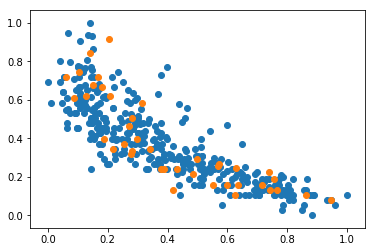

In [7]:
i = 3  #1 
plt.scatter(x_train[:, i], y_train)
plt.scatter(x_test[:, i], y_test)

### Polynomial function

In [10]:
poly = PolynomialFeatures(degree=2)

In [11]:
x_train_poly = poly.fit_transform(x_train)
x_test_poly = poly.transform(x_test)
x_train_poly.shape, x_test_poly.shape

((352, 28), (40, 28))

## Linear Regression

In [12]:
model = LinearRegression()

In [13]:
model.fit(x_train_poly, y_train)

LinearRegression()

In [14]:
model.score(x_train_poly, y_train)

0.8541660503874355

In [15]:
model.score(x_test_poly, y_test)

0.9010191069585135

## Pipeline

In [16]:
model_pipline = make_pipeline(PolynomialFeatures(degree=3), 
                              LinearRegression())
model_pipline

Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(degree=3)),
                ('linearregression', LinearRegression())])

In [17]:
model_pipline.steps

[('polynomialfeatures', PolynomialFeatures(degree=3)),
 ('linearregression', LinearRegression())]

In [18]:
model_pipline.fit(x_train, y_train)

Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(degree=3)),
                ('linearregression', LinearRegression())])

In [19]:
model_pipline.score(x_train, y_train)

0.9244799284897223

In [20]:
model_pipline.score(x_test, y_test)

0.8406936665199768